# Regresion Logistica: implementacion con Keras

### Lectura y visualiacion del set de datos

In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD
import tensorflow as tf
np.random.seed(50) # semilla
tf.random.set_seed(25)

In [79]:
data = pd.read_csv('../data/dataset(1).csv')
data

,x1,x2,y
0,1.0,7.0,1
1,4.0,0.5,0
2,6.0,3.0,1
3,1.0,4.0,0
4,3.0,4.5,1
5,5.0,4.0,1
6,3.0,2.0,0
7,5.0,6.0,1
8,7.5,1.0,1
9,5.0,1.0,0


In [80]:
data.shape

(14, 3)

In [81]:
x = data[['x1', 'x2']].to_numpy()
x.shape

(14, 2)

In [82]:
y = data['y'].to_numpy()
print(y.shape)
print(y)

(14,)
[1 0 1 0 1 1 0 1 1 0 0 1 1 0]


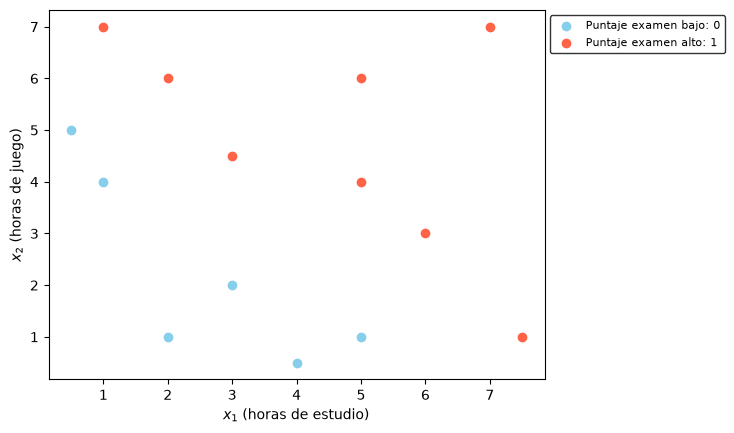

In [83]:
idx0 = np.where(y==0) # puntaje examen bajo
idx1 = np.where(y==1) # puntaje examen alto

plt.scatter(x[idx0, 0], x[idx0, 1], color='skyblue', label='Puntaje examen bajo: 0')
plt.scatter(x[idx1, 0], x[idx1, 1], color='tomato', label='Puntaje examen alto: 1')
plt.xlabel('$x_1$ (horas de estudio)')
plt.ylabel('$x_2$ (horas de juego)')
plt.legend(bbox_to_anchor=(1.0, 1.0), fontsize=8, edgecolor='black')
plt.show()

### Crear la Neurona Artifical (Modelo de clasificacion / Clasificacion binaria) en Keras

In [84]:
# contenedor vacio
modelo = Sequential()

In [85]:
# parametros de entrada del modelo
dim_entrada = x.shape[1]  # entrenamiento tendra 2 caracteristicas (x1, x2)
dim_salida = 1

# comenzar a llenar el modelo 
modelo.add(Dense(
    dim_salida, 
    input_dim=dim_entrada,
    activation='sigmoid'
))

c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [86]:
modelo.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

### Optimizador (Gradiente Descendente Estocastico) y perdida

In [87]:
optimizador = SGD(learning_rate=0.4)
modelo.compile(loss='binary_crossentropy', optimizer=optimizador, metrics=['accuracy'])

In [88]:
help(SGD)

Help on class SGD in module keras.src.optimizers.sgd:

class SGD(keras.src.optimizers.optimizer.Optimizer)
 |  SGD(
 |      learning_rate=0.01,
 |      momentum=0.0,
 |      nesterov=False,
 |      weight_decay=None,
 |      clipnorm=None,
 |      clipvalue=None,
 |      global_clipnorm=None,
 |      use_ema=False,
 |      ema_momentum=0.99,
 |      ema_overwrite_frequency=None,
 |      loss_scale_factor=None,
 |      gradient_accumulation_steps=None,
 |      name=None,
 |      **kwargs
 |  )
 |
 |  Gradient descent (with momentum) optimizer.
 |
 |  Update rule for parameter `w` with gradient `g` when `momentum` is 0:
 |
 |  ```python
 |  w = w - learning_rate * g
 |  ```
 |
 |  Update rule when `momentum` is larger than 0:
 |
 |  ```python
 |  velocity = momentum * velocity - learning_rate * g
 |  w = w + velocity
 |  ```
 |
 |  When `nesterov=True`, this rule becomes:
 |
 |  ```python
 |  velocity = momentum * velocity - learning_rate * g
 |  w = w + momentum * velocity - learning_ra

### Entrenamiento y Prediccion

In [89]:
historia = modelo.fit(x, y, 
    epochs=100,
    batch_size=x.shape[0],
    verbose=1
)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.5714 - loss: 1.1502
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6429 - loss: 0.6941
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7143 - loss: 0.6214
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6429 - loss: 0.5846
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6429 - loss: 0.5688
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5714 - loss: 0.5611
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7143 - loss: 0.5563
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5714 - loss: 0.5541
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7143 - loss: 0.5521
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5714 - loss: 0.5566
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8571 - loss: 0.5557
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5714 - l

### Comportamiento del error

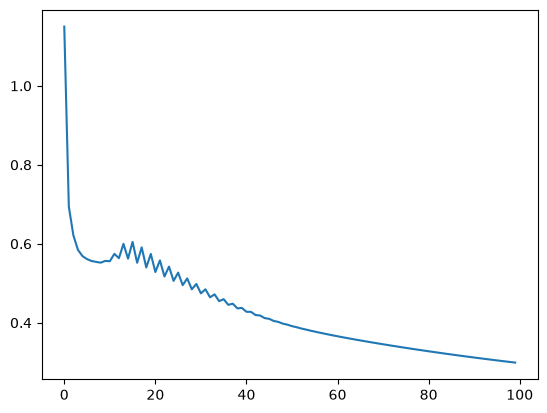

In [90]:
plt.plot(historia.history['loss']);

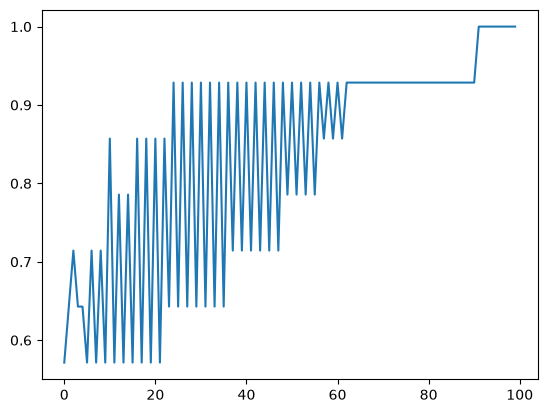

In [91]:
plt.plot(historia.history['accuracy']);

### Mostrar grafica de frontera

In [92]:
def dibujar_frontera(X, Y, modelo):
    # valor minimo y maximo y rellenado con ceros
    x_min, x_max = X[:,0].min() - .5, X[:,0].max() + .5
    y_min, y_max = X[:,1].min() - .5, X[:,1].max() + .5
    h = 0.01

    # grilla de puntos
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # predcir categorias para cada punto en la grilla
    probabilidades = modelo.predict(np.c_[xx.ravel(), yy.ravel()])
    umbral = 0.5
    Z = np.where(probabilidades > umbral, 1, 0)
    Z = Z.reshape(xx.shape)

    fig = plt.figure()
    plt.contourf(xx, yy, Z, cmap=plt.cm.Set1, alpha=0.8)

    idx0 = np.where(Y==0)
    idx1 = np.where(Y==1)
    plt.scatter(X[idx0, 0],X[idx0, 1], color='tomato', edgecolors='k', label='Puntaje examen bajo: 0')
    plt.scatter(X[idx1, 0],X[idx1, 1], color='skyblue', edgecolors='k', label='Puntaje examen alto: 1')
    plt.legend(bbox_to_anchor=(1.0, 1.0), fontsize=8, edgecolor='black')

    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

    plt.xlabel('$x_1$ (horas de estudio)')
    plt.ylabel('$x_2$ (horas de juego)')

18750/18750 ━━━━━━━━━━━━━━━━━━━━ 5s 289us/step


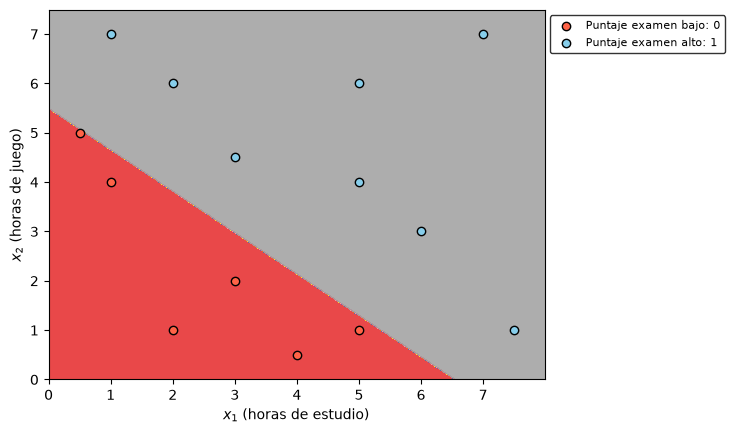

In [93]:
dibujar_frontera(x, y, modelo)